In [1]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations
from toolbox.visualization import cmap_gradient

## Frequency-analysis

In [2]:
class_task = "healthy_vs_cancer"

In [3]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

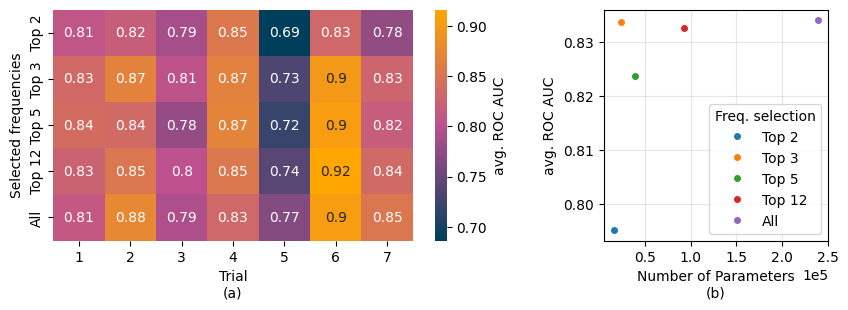

In [4]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(10, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.3)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "avg. ROC AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

## IIVV-analysis

In [5]:
class_task = "healthy_vs_cancer"

In [6]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

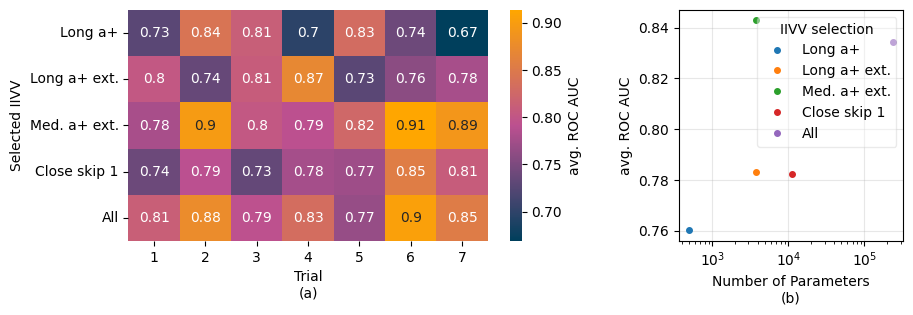

In [7]:
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(10, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.3)

# left plot
ax0 = fig.add_subplot(gs[0])
order = [
    "Long a+",
    "Long a+ ext.",
    "Med. a+ ext.",
    "Close skip 1",
    "All",
]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "avg. ROC AUC"}, ax=ax0
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig(f"results/IIVV_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Leave patients out cross validation (LPOCV)

- Only for binary classification cases

In [8]:
print("Available files")
glob("results/LPOCV*")

Available files


['results/LPOCV_healthy_vs_cancer_Top 2_Long a+.csv',
 'results/LPOCV_cancer_vs_hbd_Top 2_Long a+.csv',
 'results/LPOCV_cancer_vs_hbd_Top 2_Long a+ ext..csv',
 'results/LPOCV_healthy_vs_cancer_Top 2_Long a+ ext..csv',
 'results/LPOCV_cancer_vs_hbd_Top 2_Med. a+ ext..csv',
 'results/LPOCV_healthy_vs_cancer_Top 2_Med. a+ ext..csv',
 'results/LPOCV_cancer_vs_hbd_Top 2_Close skip 1.csv',
 'results/LPOCV_healthy_vs_cancer_Top 2_Close skip 1.csv']

In [9]:
class_task = "healthy_vs_cancer"
Fsel = "Top 2"
Msel = "Long a+ ext."

In [10]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}.csv")
df.head()

,Architecture,Fold,Random_state,ROC AUC,Sensitivity,Specificity,Recall,F1-score,Mask,Freq. selection,Task
0,SVM,1,0,0.776914,0.727273,0.684211,0.707317,0.707317,Long a+ ext.,Top 2,healthy_vs_cancer
1,RF,1,0,0.801435,0.636364,0.789474,0.707317,0.706620,Long a+ ext.,Top 2,healthy_vs_cancer
2,Lasso,1,0,0.801435,0.727273,0.684211,0.707317,0.707317,Long a+ ext.,Top 2,healthy_vs_cancer
3,SVM,2,0,0.798611,0.777778,0.750000,0.764706,0.764706,Long a+ ext.,Top 2,healthy_vs_cancer
4,RF,2,0,0.850694,0.833333,0.750000,0.794118,0.793579,Long a+ ext.,Top 2,healthy_vs_cancer


In [11]:
df.keys()

Index(['Architecture', 'Fold', 'Random_state', 'ROC AUC', 'Sensitivity',
       'Specificity', 'Recall', 'F1-score', 'Mask', 'Freq. selection', 'Task'],
      dtype='object')

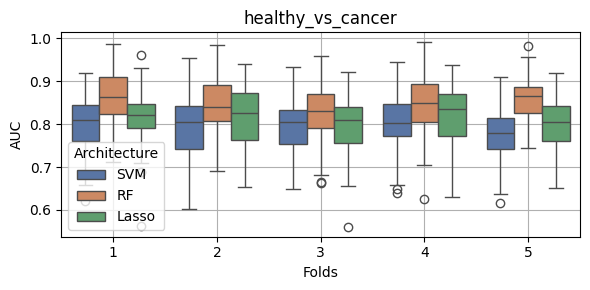

In [12]:
# results for 50 random states
plt.figure(figsize=(6, 3))
sns.boxplot(
    data=df,
    x="Fold",
    y="ROC AUC",
    hue="Architecture",
    palette="deep",  # colorblind
)
plt.title(class_task)
plt.ylabel("AUC")
plt.xlabel("Folds")
plt.legend(title="Architecture")
plt.grid(True)
plt.tight_layout()
# plt.savefig("results/boxplot_architecture", bbox_inches="tight")
plt.show()

In [14]:
summary = evaluate_combinations(
    df,
    groupby_cols=["Architecture", "Mask", "Task", "Freq. selection"],
    primary_metric="ROC AUC",
)
print("\n\t\t================== Summary table ==================")
print(summary)


		================== Summary table ==================
  Architecture          Mask               Task Freq. selection  ROC AUC_mean  \
0           RF  Long a+ ext.  healthy_vs_cancer           Top 2        0.8478   
1        Lasso  Long a+ ext.  healthy_vs_cancer           Top 2        0.8089   
2          SVM  Long a+ ext.  healthy_vs_cancer           Top 2        0.7927   

   ROC AUC_std  ROC AUC_max  Sensitivity_mean  Sensitivity_std  \
0       0.0675       0.9926            0.7557           0.1109   
1       0.0702       0.9615            0.7658           0.1092   
2       0.0679       0.9542            0.7723           0.1060   

   Sensitivity_max  Specificity_mean  Specificity_std  Specificity_max  \
0              1.0            0.8162           0.0851           1.0000   
1              1.0            0.7381           0.1096           1.0000   
2              1.0            0.7240           0.1020           0.9474   

   Recall_mean  Recall_std  Recall_max  F1-score_mean  F1-

## Leave patients out cross validation (LPOCV) -- combined

In [18]:
from pathlib import Path

import pandas as pd

files = Path("results").glob("LPOCV_*.csv")
combined = pd.concat(
    [pd.read_csv(f).assign(source_file=f.name) for f in files],
    ignore_index=True,
)

In [19]:
combined

,Architecture,Fold,Random_state,ROC AUC,Sensitivity,Specificity,Recall,F1-score,Mask,Freq. selection,Task,source_file
0,SVM,1,0,0.700957,0.636364,0.736842,0.682927,0.682927,Long a+,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Long a+.csv
1,RF,1,0,0.765550,0.590909,0.789474,0.682927,0.681036,Long a+,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Long a+.csv
2,Lasso,1,0,0.715311,0.727273,0.631579,0.682927,0.682165,Long a+,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Long a+.csv
3,SVM,2,0,0.840278,0.833333,0.750000,0.794118,0.793579,Long a+,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Long a+.csv
4,RF,2,0,0.857639,0.833333,0.687500,0.764706,0.763055,Long a+,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Long a+.csv
...,...,...,...,...,...,...,...,...,...,...,...,...
5982,RF,4,49,0.858333,0.777778,0.850000,0.815789,0.815404,Close skip 1,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Close skip 1.csv
5983,Lasso,4,49,0.861111,0.777778,0.750000,0.763158,0.763322,Close skip 1,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Close skip 1.csv
5984,SVM,5,49,0.841667,0.888889,0.800000,0.842105,0.842105,Close skip 1,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Close skip 1.csv
5985,RF,5,49,0.905556,0.722222,0.900000,0.815789,0.813842,Close skip 1,Top 2,healthy_vs_cancer,LPOCV_healthy_vs_cancer_Top 2_Close skip 1.csv


In [20]:
summary = evaluate_combinations(
    combined,
    groupby_cols=["Architecture", "Mask", "Task", "Freq. selection"],
    primary_metric="ROC AUC",
)
print("\n\t\t================== Summary table ==================")
print(summary)


		================== Summary table ==================
   Architecture          Mask               Task Freq. selection  \
0            RF  Close skip 1  healthy_vs_cancer           Top 2   
1            RF  Med. a+ ext.  healthy_vs_cancer           Top 2   
2            RF  Long a+ ext.  healthy_vs_cancer           Top 2   
3         Lasso  Close skip 1  healthy_vs_cancer           Top 2   
4            RF  Close skip 1      cancer_vs_hbd           Top 2   
5            RF       Long a+  healthy_vs_cancer           Top 2   
6            RF  Long a+ ext.      cancer_vs_hbd           Top 2   
7         Lasso  Close skip 1      cancer_vs_hbd           Top 2   
8            RF  Med. a+ ext.      cancer_vs_hbd           Top 2   
9         Lasso  Long a+ ext.  healthy_vs_cancer           Top 2   
10           RF       Long a+      cancer_vs_hbd           Top 2   
11          SVM  Med. a+ ext.  healthy_vs_cancer           Top 2   
12          SVM  Long a+ ext.  healthy_vs_cancer           To